# Fitting a multi-stage protocol with an event (optim_param_protocol)

In vitro convection model, same protocol as the "events and stages" figure of the paper:
- stage "static"  (0-50 s): static solution, mass transfer coefficient k,
- stage "stirred" (50-150 s): stirred solution, k multiplied by 10,
- event "open" at t = 100 s: the vial is opened, the headspace concentration Cg is reset to 0.

Synthetic data are simulated with known parameters plus 1 % noise, then the two stage-specific
mass transfer coefficients (k@static, k@stirred) and the PTR-MS response time (tMS) are
fitted from wrong starting values. "k@static" only concerns the stage named "static";
a name without "@" (here "tMS") is shared by every stage.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from digimouth import dynamic_model as dm
from digimouth import existing_models as exmod
from digimouth import optimization as opt

SAVE_PATH = None  # e.g. "fit_protocol_in_vitro.png" to save the figure

## Model and protocol

In [2]:
Kaw = 7e-3                     # air/water partition coefficient
k_static = 1.38e-2             # cm/s, mass transfer coefficient (static solution)
k_stirred = 10 * k_static      # cm/s, stirred solution
Cl_ini = 2                     # initial concentration in the solution
A = np.pi * (3.7 / 2) ** 2     # cm^2, interface area
Dg = 2.63                      # cm^3/s, PTR-MS gas flow
Vr, Vl = 28, 2                 # cm^3, headspace and liquid volumes
tMS = 1.0                      # s, PTR-MS response time


def convection_model(k, t_ms):
    return exmod.generate_convection_model(Kaw_initial=Kaw, k_initial=k, A_ini=A, Dg_ini=Dg,
                                           Vr=Vr, Vl=Vl, tMS=t_ms)


y0 = {"Cl": Cl_ini, "Cg": Kaw * Cl_ini, "CMS": 0}
events = pd.DataFrame({"time": [100.0], "type": ["open"]})
true_stages = [{"name": "static", "t_start": 0, "t_end": 50, "model": convection_model(k_static, tMS)},
               {"name": "stirred", "t_start": 50, "t_end": 150, "model": convection_model(k_stirred, tMS)}]
event_funcs = true_stages[0]["model"].event_funcs

## Synthetic data: true parameters + 1 % multiplicative noise

In [3]:
truth = dm.run_stages(true_stages, y0, df_event=events, event_func_dict=event_funcs, n_points=600)
truth = truth.drop_duplicates("time", keep="last")   # keep the state just after the event
t_exp = np.linspace(0, 150, 300)
rng = np.random.default_rng(0)
y_exp = np.interp(t_exp, truth["time"], truth["CMS"]) * (1 + 0.01 * rng.standard_normal(t_exp.size))

## Fit from wrong starting values (same k in both stages, tMS = 3 s)

In [4]:
start_stages = [{**st, "model": convection_model(5e-3, 3.0)} for st in true_stages]
params_start = {"k@static": 5e-3, "k@stirred": 5e-3, "tMS": 3.0}
bounds = {"k@static": (1e-4, 1), "k@stirred": (1e-4, 1), "tMS": (1e-2, 10)}

fit = opt.optim_param_protocol(t_exp, y_exp, start_stages, y0, params=params_start, bounds=bounds,
                               events=events, normalization=False, n_points=600)

true_values = {"k@static": k_static, "k@stirred": k_stirred, "tMS": tMS}
print(f"success: {fit['success']}  RMSE: {fit['rmse']:.2e}")
for name, value in fit["opt_params"].items():
    low, high = fit["conf_intervals"][name]
    print(f"{name:10s} true={true_values[name]:.4g}  fitted={value:.4g}  95% CI=[{low:.4g}, {high:.4g}]")
# Note: these intervals assume independent residuals (see doc/known_issues.md).

success: True  RMSE: 3.90e-05
k@static   true=0.0138  fitted=0.01387  95% CI=[0.01366, 0.01409]
k@stirred  true=0.138  fitted=0.1378  95% CI=[0.1374, 0.1381]
tMS        true=1  fitted=0.9914  95% CI=[0.9905, 0.9923]

## Same fit without the opening event

In [5]:
# Same fit without the event: the model cannot reproduce the curve
fit_no_event = opt.optim_param_protocol(t_exp, y_exp, start_stages, y0, params=params_start, bounds=bounds,
                                        normalization=False, n_points=600)
print(f"RMSE without the opening event: {fit_no_event['rmse']:.2e}")

RMSE without the opening event: 5.51e-04

## Figure

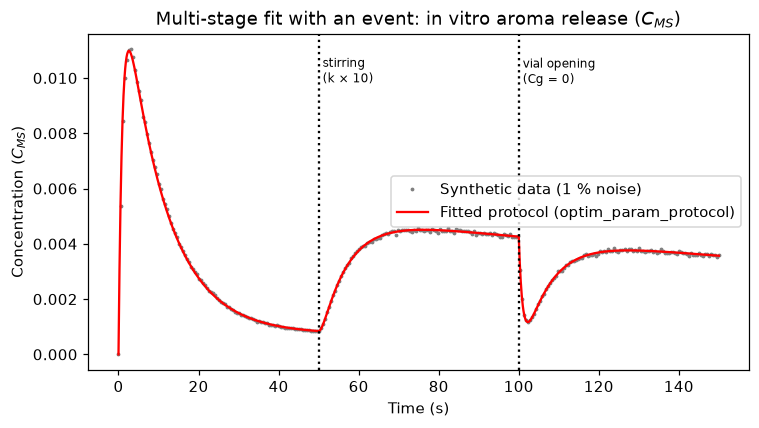

In [6]:
sim = dm.run_stages(fit["opt_stages"], y0, df_event=events, event_func_dict=event_funcs, n_points=600)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t_exp, y_exp, ".", ms=3, color="grey", label="Synthetic data (1 % noise)")
ax.plot(sim["time"], sim["CMS"], "r-", label="Fitted protocol (optim_param_protocol)")
ax.axvline(50, ls=":", c="k")
ax.axvline(100, ls=":", c="k")
ymax = ax.get_ylim()[1]
ax.text(51, 0.93 * ymax, "stirring\n(k × 10)", fontsize=8, va="top")
ax.text(101, 0.93 * ymax, "vial opening\n(Cg = 0)", fontsize=8, va="top")
ax.set_title("Multi-stage fit with an event: in vitro aroma release ($C_{MS}$)")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Concentration ($C_{MS}$)")
ax.legend(loc="center right")
fig.tight_layout()
if SAVE_PATH:
    fig.savefig(SAVE_PATH, dpi=150)
plt.show()